In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_recall_curve
)

In [31]:
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.regularizers import l1
from tensorflow.keras.optimizers import Adam

In [32]:
df = pd.read_csv("creditcard.csv")

print("Dataset shape:", df.shape)



Dataset shape: (284807, 31)


In [33]:
print(df.head())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [34]:
print("\nClass distribution:")
print(df["Class"].value_counts())


Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64


In [35]:
X = df.drop("Class", axis=1)
y = df["Class"]

In [36]:
X = X.drop("Time", axis=1)
scaler = StandardScaler()
X["Amount"] = scaler.fit_transform(X[["Amount"]])

In [37]:
X_normal = X[y == 0]
X_fraud = X[y == 1]
print("Normal transactions:", len(X_normal))
print("Fraud transactions:", len(X_fraud))

Normal transactions: 284315
Fraud transactions: 492


In [38]:
X_train, X_validation = train_test_split(
    X_normal,
    test_size=0.20,
    random_state=42
)

print("Training normal transactions:", X_train.shape)
print("Validation normal transactions:", X_validation.shape)

Training normal transactions: (227452, 29)
Validation normal transactions: (56863, 29)


In [39]:
input_dim = X_train.shape[1]

input_layer = Input(shape=(input_dim,))

encoder = Dense(
    16,
    activation="relu"
)(input_layer)

latent = Dense(
    8,
    activation="relu",
    activity_regularizer=l1(1e-5),
    name="latent"
)(encoder)

decoder = Dense(
    16,
    activation="relu"
)(latent)

output_layer = Dense(
    input_dim,
    activation="linear"
)(decoder)


autoencoder = Model(
    inputs=input_layer,
    outputs=output_layer
)

autoencoder.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 29)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 16)                  │             480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ latent (Dense)                       │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 29)                  │             493 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,253 (4.89 KB)

 Trainable params: 1,253 (4.89 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
autoencoder.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
)


In [41]:
history = autoencoder.fit(
    X_train,
    X_train,
    epochs=50,
    batch_size=256,
    validation_data=(X_validation, X_validation),
    shuffle=True,
    verbose=1
)


Epoch 1/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.6564 - val_loss: 0.4579
Epoch 2/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.4042 - val_loss: 0.3835
Epoch 3/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.3686 - val_loss: 0.3676
Epoch 4/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.3565 - val_loss: 0.3531
Epoch 5/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.3408 - val_loss: 0.3347
Epoch 6/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.3281 - val_loss: 0.3248
Epoch 7/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.3214 - val_loss: 0.3197
Epoch 8/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.3172 - val_loss: 0.3183
Epoch 9/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.3144 - val_loss: 0.3152
Epoch 10/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.3118 - val_loss: 0.3131
Epoch 11/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.3097 - val_loss: 0.3118
Epoch 12/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step

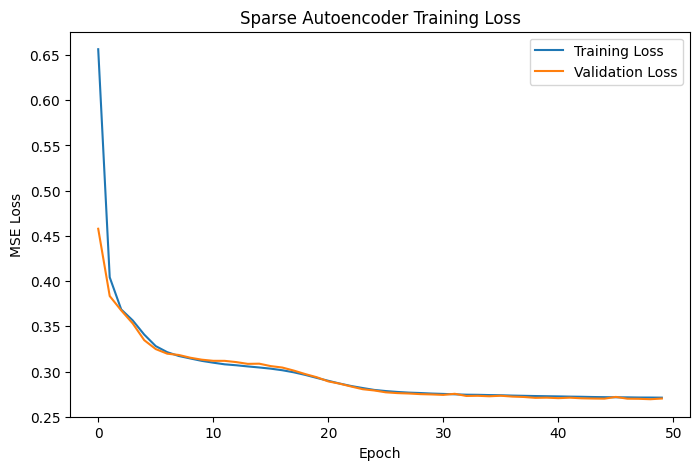

In [42]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Sparse Autoencoder Training Loss")

plt.legend()
plt.show()

In [43]:
X_val_pred = autoencoder.predict(
    X_validation,
    verbose=0
)

In [44]:
normal_errors = np.mean(
    np.square(
        X_validation.values - X_val_pred
    ),
    axis=1
)

print("Average reconstruction loss:",
      np.mean(normal_errors))


print("Maximum normal reconstruction error:",
      np.max(normal_errors))

Average reconstruction loss: 0.2698486522493111
Maximum normal reconstruction error: 101.96402735507348


In [46]:
threshold = np.percentile(
    normal_errors,
    99.5
)

print("Anomaly threshold:", threshold)

Anomaly threshold: 1.3062782744014818


In [47]:
X_test = pd.concat(
    [X_validation, X_fraud],
)

y_test = np.concatenate([
    np.zeros(len(X_validation)),  # Normal
    np.ones(len(X_fraud))         # Fraud
])

In [48]:
indices = np.random.RandomState(42).permutation(
    len(X_test)
)

X_test = X_test.iloc[indices]
y_test = y_test[indices]

In [49]:
X_test_pred = autoencoder.predict(
    X_test,
    verbose=0
)

In [50]:
test_errors = np.mean(
    np.square(
        X_test.values - X_test_pred
    ),
    axis=1
)

In [51]:
y_pred = (
    test_errors > threshold
).astype(int)

print("Number of detected anomalies:",
      np.sum(y_pred))


Number of detected anomalies: 683


In [52]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[56578   285]
 [   94   398]]


In [53]:
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)


Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00     56863
       Fraud       0.58      0.81      0.68       492

    accuracy                           0.99     57355
   macro avg       0.79      0.90      0.84     57355
weighted avg       0.99      0.99      0.99     57355



In [54]:
fraud_index = df[df["Class"] == 1].index[0]

print("Transaction index:", fraud_index)
print(df.loc[fraud_index])

Transaction index: 541
Time      406.000000
V1         -2.312227
V2          1.951992
V3         -1.609851
V4          3.997906
V5         -0.522188
V6         -1.426545
V7         -2.537387
V8          1.391657
V9         -2.770089
V10        -2.772272
V11         3.202033
V12        -2.899907
V13        -0.595222
V14        -4.289254
V15         0.389724
V16        -1.140747
V17        -2.830056
V18        -0.016822
V19         0.416956
V20         0.126911
V21         0.517232
V22        -0.035049
V23        -0.465211
V24         0.320198
V25         0.044519
V26         0.177840
V27         0.261145
V28        -0.143276
Amount      0.000000
Class       1.000000
Name: 541, dtype: float64


In [55]:
fraud_indices = df[df["Class"] == 1].index[:10]

print(fraud_indices.tolist())

[541, 623, 4920, 6108, 6329, 6331, 6334, 6336, 6338, 6427]


In [56]:
index = int(input("Enter transaction index: "))

transaction = X.loc[[index]]

reconstructed = autoencoder.predict(
    transaction,
    verbose=0
)

reconstruction_loss = np.mean(
    np.square(
        transaction.values - reconstructed
    ),
    axis=1
)[0]

if reconstruction_loss > threshold:
    result = "FRAUD"
else:
    result = "NORMAL"

print("\nReconstruction Loss:", reconstruction_loss)
print("Threshold:", threshold)
print("Prediction:", result)

Enter transaction index:  4920



Reconstruction Loss: 3.245797108123707
Threshold: 1.3062782744014818
Prediction: FRAUD
